# Notebook testi

Tämä notebook on testi, jonka tarkoituksena on kokeilla saanko tämän notebookin toimimaan selaimessa, ja saanko grafiikoita toimimaan. Tarkoituksena on myös selvittää, voiko soluja ajaa normaaliin tapaan selaimessa ja voiko niitä muokata itse. Notebookin rakentamisessa olen käyttänyt Jupyterin templaattia: [templaatti](https://jupyterlite.readthedocs.io/en/stable/quickstart/deploy.html).

## Tässä tekstikentässä on LaTeX-ladontaa ja bulletteja

Notebookiin saadaan upotettua kaikenlaista mediaa, kuten esimerkiksi
- Videoita
- Kuvia
- Ääntä

# Lähdetään liikkeelle esittämällä muutama kvanttitila:

$$ |\psi_1\rangle = |0\rangle = \begin{bmatrix} 1 \\ 0   \end{bmatrix}$$

$$ |\psi_2\rangle = \frac{1}{\sqrt{2}}( |0\rangle + |1\rangle ) = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 \\ 1   \end{bmatrix}$$

$$ |\psi_3\rangle = \frac{1}{\sqrt{2}}( |0\rangle + i |1\rangle ) = \frac{1}{\sqrt{2}}\begin{bmatrix} 1 \\ i   \end{bmatrix}$$

Nämä tilat voidaan kirjoittaa kolmpeksivektoreina Pythonilla käyttämällä `numpy`-kirjastoa

In [1]:
import numpy as np

psi1 = np.array([ 1, 0 ])
psi2 = [ 1/np.sqrt(2), 1/np.sqrt(2) ]      
psi3 = [ 1/np.sqrt(2), 1j/np.sqrt(2) ]

print(psi1)
print(psi2)
print(psi3)

[1 0]
[np.float64(0.7071067811865475), np.float64(0.7071067811865475)]
[np.float64(0.7071067811865475), 0.7071067811865475j]


## Esimerkki 1: Seuraavaksi esitellään satunnaista dataa

Tässä esimerkissä kuvataan satunnaista dataa. Satunnainen data generoidaan `numpy`:n avulla, ja kuvaaja piirretään kirjaston `matplotlib`avulla. Kokeile tehdä muutoksia kuvaajaan.

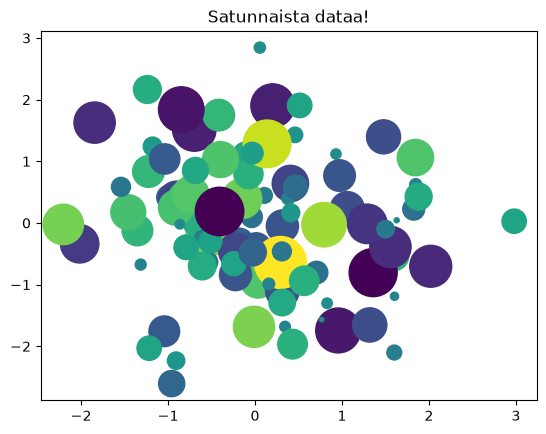

In [2]:
import numpy as np
from matplotlib import pyplot as plt

# Luodaan 100 satunnaista datapistettä muodossa (x_i, y_i, scale)
x, y, scale = np.random.randn(3, 100)
fig, ax = plt.subplots() # liittyy kuvaajan piirtämiseen

# Piirretään datapisteet kuvaajaan
ax.scatter(x=x, y=y, c=scale, s=np.abs(scale) * 500)
ax.set(title="Satunnaista dataa!")
plt.show()


## Esimerkki 2: Kubitin mittaus

Kubitin tila ilmoitetaan tilavektorina

$$
|\psi\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle
+ e^{i\phi}\sin\left(\frac{\theta}{2}\right)|1\rangle
$$

Mittaustulosten todennäköisyydet ovat

$$
P(0) = \left|\cos\left(\frac{\theta}{2}\right)\right|^2
$$

ja

$$
P(1) = \left|e^{i\phi}\sin\left(\frac{\theta}{2}\right)\right|^2
$$

Muuta kulmia ja katso, mitä mittaustodennäköisyyksille tapahtuu.

In [11]:
import numpy as np
import ipywidgets as widgets
from matplotlib import pyplot as plt
from IPython.display import display, clear_output

def probabilities(theta, phi):
    p0 = np.cos(theta / 2)
    p1 = np.exp(1j * phi) * np.sin(theta / 2)

    P0 = np.abs(p0)**2
    P1 = np.abs(p1)**2

    return P0, P1

slider_theta = widgets.FloatSlider(
    value=np.pi / 2,
    min=0,
    max=np.pi,
    step=0.01,
    description='theta:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.2f',
)

slider_phi = widgets.FloatSlider(
    value=0,
    min=0,
    max=2 * np.pi,
    step=0.01,
    description='phi:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.2f',
)

output = widgets.Output()

def update_plot(theta, phi):
    P0, P1 = probabilities(theta, phi)

    with output:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(6, 3))

        ax.bar(['0', '1'], [P0, P1])
        ax.set_ylim(0, 1)
        #ax.set_ylabel('xx')
        ax.set_title('Mittaustulosten todennäköisyys')

        for i, p in enumerate([P0, P1]):
            ax.text(i, p + 0.03, f'{p:.3f}', ha='center')

        plt.show()
        plt.close(fig)

ui = widgets.VBox([slider_theta, slider_phi])

widgets.interactive_output(
    update_plot,
    {'theta': slider_theta, 'phi': slider_phi}
)

display(ui, output)

Output()